# Robustness analysis — shifted test-set evaluation

Reads `results/shift_{MODEL}_{SPLIT}_combined_per_case.csv` and
`results/shift_{MODEL}_{SPLIT}_summary.json`.

Run first:
```bash
python scripts/09_robustness.py \
    --checkpoint models.nosync/baseline/best.pth \
    --model-name baseline --split val
```

**Conditions:**

| Condition | In DR training? | Notes |
|-----------|----------------|-------|
| clean | — | unmodified baseline |
| gain_high | yes | uniform +50% gain |
| speckle | yes | multiplicative Rayleigh (mean≈1, std≈0.47); spatially uncorrelated |
| blur | yes | anisotropic Gaussian PSF (axial σ=2, lateral σ=1) |
| attenuation | yes | depth gain ramp 1.2→0.5 |
| low_res | **no** | ×4 downsample/upsample |
| speckle_corr | **no** | Rayleigh smoothed with σ=4px Gaussian, renorm. to mean≈1 |

In [1]:
import os, sys, json
from pathlib import Path

_here = Path.cwd()
while not (_here / 'pyproject.toml').exists() and _here != _here.parent:
    _here = _here.parent
os.chdir(_here)
sys.path.insert(0, str(_here / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# --- configure which run to load ---
MODEL = "baseline"
SPLIT = "val"   # change to "test" once configuration is locked
# -----------------------------------

RESULTS = Path('results')
PREFIX = f'shift_{MODEL}_{SPLIT}'
_required = [RESULTS / f'{PREFIX}_combined_per_case.csv', RESULTS / f'{PREFIX}_summary.json']
_missing = [str(p) for p in _required if not p.exists()]
if _missing:
    raise FileNotFoundError(
        f'Missing: {_missing}\n'
        f'Run: python scripts/09_robustness.py '
        f'--checkpoint <ckpt> --model-name {MODEL} --split {SPLIT}'
    )

df = pd.read_csv(RESULTS / f'{PREFIX}_combined_per_case.csv')
with open(RESULTS / f'{PREFIX}_summary.json') as f:
    summary = json.load(f)

STRUCTURES = ['lv_cavity', 'myocardium', 'left_atrium']
STRUCT_LABELS = ['LV cavity', 'Myocardium', 'Left atrium']
CONDITION_ORDER = ['clean', 'gain_high', 'speckle', 'blur', 'attenuation', 'low_res', 'speckle_corr']
HELD_OUT = {'low_res', 'speckle_corr'}

print(f'Model: {MODEL} | Split: {SPLIT}')
print(f'Rows: {len(df)} | Conditions: {sorted(df["condition"].unique())}')

Model: baseline | Split: val
Rows: 2100 | Conditions: ['attenuation', 'blur', 'clean', 'gain_high', 'low_res', 'speckle', 'speckle_corr']


## 1. Mean Dice per condition — summary table

In [2]:
rows = []
for cond in CONDITION_ORDER:
    cdf = df[df['condition'] == cond]
    row = {'condition': cond, 'held_out': cond in HELD_OUT}
    for s in STRUCTURES:
        row[s] = cdf[f'dice_{s}'].mean()
    rows.append(row)

tbl = pd.DataFrame(rows).set_index('condition')
clean_row = tbl.loc['clean', STRUCTURES]
tbl['held_out'] = tbl['held_out'].map({True: '✓', False: ''})

# Dice drop row (condition − clean)
delta = tbl.loc[CONDITION_ORDER[1:], STRUCTURES].subtract(clean_row)
delta.index = [f'Δ {c}' for c in CONDITION_ORDER[1:]]

display_tbl = pd.concat([tbl[STRUCTURES + ['held_out']], delta[STRUCTURES]])
display_tbl.round(3)

,lv_cavity,myocardium,left_atrium,held_out
clean,0.940987,0.880838,0.911353,
gain_high,0.936035,0.873947,0.899836,
speckle,0.886774,0.778093,0.800272,
blur,0.937386,0.873579,0.909456,
attenuation,0.93994,0.879428,0.909954,
low_res,0.928443,0.861462,0.908286,✓
speckle_corr,0.698438,0.638834,0.542801,✓
Δ gain_high,-0.004952,-0.006891,-0.011517,NaN
Δ speckle,-0.054214,-0.102745,-0.11108,NaN
Δ blur,-0.003601,-0.007259,-0.001896,NaN


## 2. Dice heatmap — conditions × structures

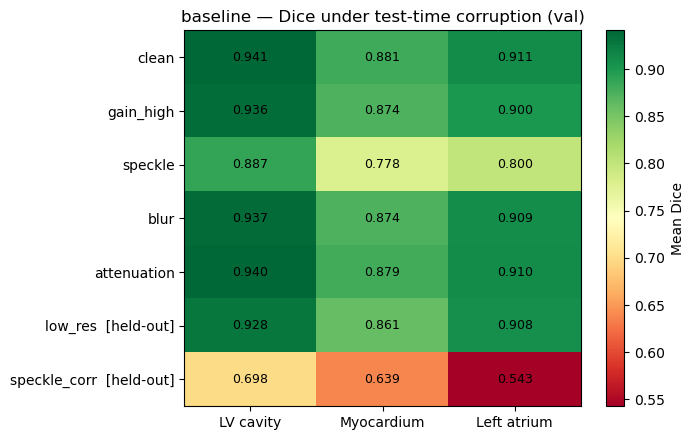

In [3]:
heat = pd.DataFrame(
    {s: [df[df['condition']==c][f'dice_{s}'].mean() for c in CONDITION_ORDER]
     for s in STRUCTURES},
    index=CONDITION_ORDER,
).astype(float)

vmin, vmax = heat.values.min(), heat.values.max()

fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(heat.values, cmap='RdYlGn', vmin=vmin, vmax=vmax, aspect='auto')
ax.set_xticks(range(len(STRUCTURES)))
ax.set_xticklabels(STRUCT_LABELS)
ax.set_yticks(range(len(CONDITION_ORDER)))
yticklabels = [f'{c}  [held-out]' if c in HELD_OUT else c for c in CONDITION_ORDER]
ax.set_yticklabels(yticklabels)
for i, row in enumerate(heat.values):
    for j, val in enumerate(row):
        ax.text(j, i, f'{val:.3f}', ha='center', va='center', fontsize=9)
fig.colorbar(im, ax=ax, label='Mean Dice')
ax.set_title(f'{MODEL} — Dice under test-time corruption ({SPLIT})')
fig.tight_layout()
plt.savefig(RESULTS / f'{PREFIX}_heatmap.png', dpi=150)
plt.show()

## 3. Dice drop (Δ = condition − clean) per structure

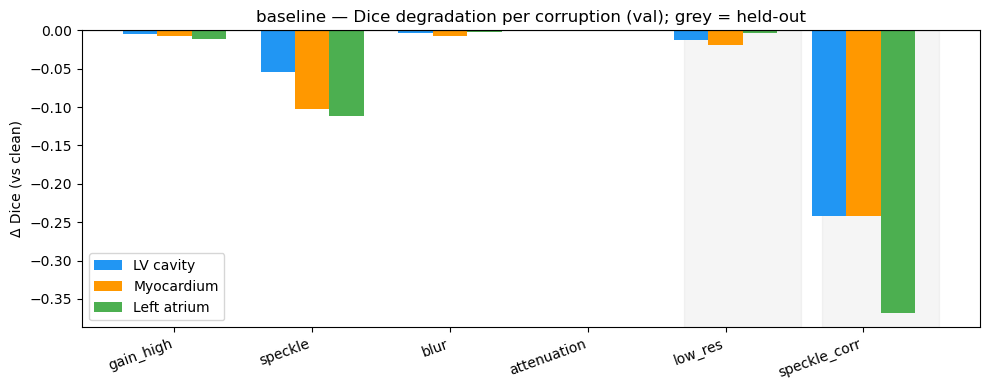

In [4]:
clean_means = {s: df[df['condition'] == 'clean'][f'dice_{s}'].mean() for s in STRUCTURES}
corrupted = [c for c in CONDITION_ORDER if c != 'clean']

x = np.arange(len(corrupted))
width = 0.25
fig, ax = plt.subplots(figsize=(10, 4))
colors = ['#2196F3', '#FF9800', '#4CAF50']
for k, (s, label) in enumerate(zip(STRUCTURES, STRUCT_LABELS)):
    deltas = [df[df['condition'] == c][f'dice_{s}'].mean() - clean_means[s] for c in corrupted]
    bars = ax.bar(x + k * width, deltas, width, label=label, color=colors[k])

ax.axhline(0, color='black', linewidth=0.8)
# Mark held-out conditions
for i, c in enumerate(corrupted):
    if c in HELD_OUT:
        ax.axvspan(i - 0.05, i + 3*width + 0.05, alpha=0.08, color='grey', zorder=0)
ax.set_xticks(x + width)
ax.set_xticklabels(corrupted, rotation=20, ha='right')
ax.set_ylabel('Δ Dice (vs clean)')
ax.set_title(f'{MODEL} — Dice degradation per corruption ({SPLIT}); grey = held-out')
ax.legend()
fig.tight_layout()
plt.savefig(RESULTS / f'{PREFIX}_delta.png', dpi=150)
plt.show()

## 4. Quality-tier breakdown — does `poor` degrade faster?

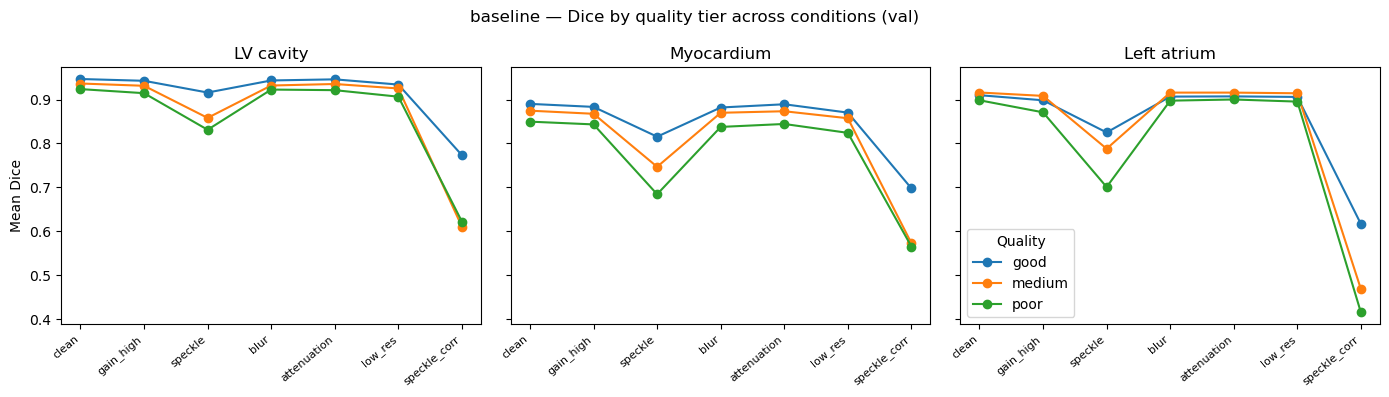

In [5]:
quality_tiers = sorted(df['quality'].dropna().unique())
fig, axes = plt.subplots(1, len(STRUCTURES), figsize=(14, 4), sharey=True)

for ax, (s, label) in zip(axes, zip(STRUCTURES, STRUCT_LABELS)):
    for tier in quality_tiers:
        means = [
            df[(df['condition'] == c) & (df['quality'] == tier)][f'dice_{s}'].mean()
            for c in CONDITION_ORDER
        ]
        ax.plot(range(len(CONDITION_ORDER)), means, marker='o', label=tier)
    ax.set_title(label)
    ax.set_xticks(range(len(CONDITION_ORDER)))
    ax.set_xticklabels(CONDITION_ORDER, rotation=40, ha='right', fontsize=8)

axes[0].set_ylabel('Mean Dice')
axes[-1].legend(title='Quality')
fig.suptitle(f'{MODEL} — Dice by quality tier across conditions ({SPLIT})')
fig.tight_layout()
plt.savefig(RESULTS / f'{PREFIX}_quality.png', dpi=150)
plt.show()

## 5. Example images — one corrupted frame per condition

In [6]:
from echo_seg.evaluation.shift_eval import CORRUPTIONS
from echo_seg.data.dataset import _load_image

manifest = pd.read_csv('data/manifest.csv')
test_row = df[df['condition'] == 'clean'].iloc[0]
img_path = manifest[
    (manifest['patient_id'] == test_row['patient_id']) &
    (manifest['view'] == test_row['view']) &
    (manifest['phase'] == test_row['phase'])
]['image'].values[0]

arr, _ = _load_image(img_path)
img_t = torch.from_numpy(arr).unsqueeze(0).unsqueeze(0)

n = len(CORRUPTIONS)
fig, axes = plt.subplots(1, n, figsize=(3 * n, 3))
for ax, (name, fn) in zip(axes, CORRUPTIONS.items()):
    np.random.seed(42)
    out = fn(img_t) if fn else img_t
    title = f'{name}\n[held-out]' if name in HELD_OUT else name
    ax.imshow(out[0, 0].numpy(), cmap='gray', vmin=0, vmax=1)
    ax.set_title(title, fontsize=8)
    ax.axis('off')

fig.suptitle(
    f'Patient {test_row["patient_id"]} · {test_row["view"]} · {test_row["phase"]}',
    fontsize=9,
)
fig.tight_layout()
plt.close(fig)  # skipped: would embed CAMUS frames in notebook output

## 6. Baseline vs DR comparison

Run after P2 is complete:
```bash
python scripts/09_robustness.py \
    --checkpoint models.nosync/dr/best.pth \
    --model-name dr --split val
```
Then set `MODEL_B = "dr"` below and re-run.

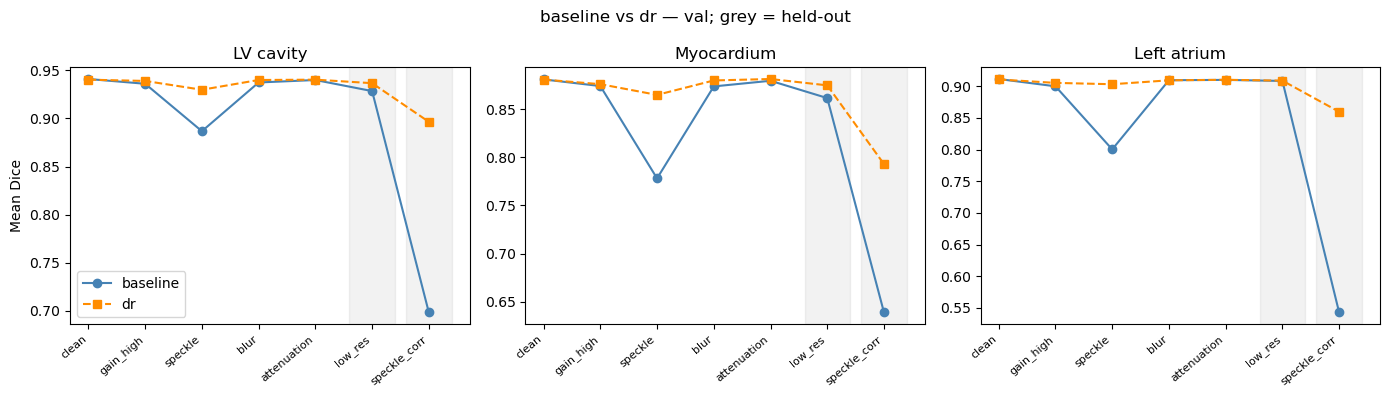

In [7]:
MODEL_B = "dr"
prefix_b = f'shift_{MODEL_B}_{SPLIT}'
fpath_b = RESULTS / f'{prefix_b}_combined_per_case.csv'

if not fpath_b.exists():
    print(f'DR results not found at {fpath_b}. Run 09_robustness.py for the DR arm first.')
else:
    df_b = pd.read_csv(fpath_b)

    fig, axes = plt.subplots(1, len(STRUCTURES), figsize=(14, 4), sharey=False)
    for ax, (s, label) in zip(axes, zip(STRUCTURES, STRUCT_LABELS)):
        base_means = [df[df['condition']==c][f'dice_{s}'].mean() for c in CONDITION_ORDER]
        dr_means   = [df_b[df_b['condition']==c][f'dice_{s}'].mean() for c in CONDITION_ORDER]
        x = range(len(CONDITION_ORDER))
        ax.plot(x, base_means, 'o-', label=MODEL, color='steelblue')
        ax.plot(x, dr_means,   's--', label=MODEL_B, color='darkorange')
        for i, c in enumerate(CONDITION_ORDER):
            if c in HELD_OUT:
                ax.axvspan(i - 0.4, i + 0.4, alpha=0.1, color='grey', zorder=0)
        ax.set_title(label)
        ax.set_xticks(range(len(CONDITION_ORDER)))
        ax.set_xticklabels(CONDITION_ORDER, rotation=40, ha='right', fontsize=8)

    axes[0].set_ylabel('Mean Dice')
    axes[0].legend()
    fig.suptitle(f'{MODEL} vs {MODEL_B} — {SPLIT}; grey = held-out')
    fig.tight_layout()
    plt.savefig(RESULTS / f'shift_comparison_{SPLIT}.png', dpi=150)
    plt.show()